# Fall 2024 Midterm Exam - Section 2: Multiple Choice Coding Questions (6 points each)

Edit this file to take the second part of the midterm. Uncomment the line that best solves the coding problem to produce the intended result.

Each question in this section only has one correct answer.

Be sure to save your work, then *add, commit, and push* your files, and check in your online GitHub repository that you submitted your work successfully.

This work will be graded manually.

**TIP: You can comment or uncomment blocks of code using `Ctrl` + `/`**.

## Imports

This cell imports the packages you need for this section of the exam. Be sure to **select the correct kernel** that has the right Python dependencies installed. If you are using the provided Dev Container, this will be the `.venv` environment.

In [ ]:
import numpy as np
import torch  # noqa: F401 - Used in the commented answer choices.
from torch.utils.data import Dataset  # noqa: F401 - Used in the answer choices.
from torchvision.transforms import v2  # type: ignore[import-untyped]  # noqa: F401

from exam.data_generators import generate_xor_dataset
from exam.data_visualizers import (
    plot_2d_decision_surface_and_features,
    scatter_plot_dataset,
)

np.random.seed(42)

## Problem 11: Linear Functions

Uncomment the line which computes a **linear** function of $x$.

In [ ]:
# Setup code
# Later problems reuse x with different array shapes and dtypes.
x: np.ndarray = np.arange(0, 10)
fx = np.zeros(x.shape)
w = np.random.random(x.shape)
# End setup code

# Choice A:
# fx = np.max(w * x)

# Choice B:
# fx = np.exp(w*x)

# Choice C:
# fx = x**3

# Choice D:
# fx = np.convolve(x, w)

Explain your answer (1-2 sentences):

## Problem 12: Nonlinear Functions

Uncomment the line which computes a **nonlinear** function of $x$.

In [ ]:
# Setup code
x = np.arange(0, 10)
fx = np.zeros(x.shape)
w = np.random.random(x.shape)
# End setup code


def rectified_linear_unit(x: np.ndarray) -> np.ndarray:
    return (x + np.abs(x)) / 2


# Choice A:
# fx = rectified_linear_unit(x)

# Choice B:
# fx = np.sum(w**2 * x)

# Choice C:
# fx = np.convolve(2*w, x)

# Choice D:
# fx = np.convolve(np.exp(w), np.convolve(2*w, x))

Explain your answer (1-2 sentences):

## Problem 13: Activations

Uncomment the line which specifies a basic fully connected, multi-layer neural network with a `tanh` activation function and executes inference on an array called `x`. Select the choice that cannot be algebraically simplify to a single layer network.

In [ ]:
# Setup code
n_samples = 5
n_features = 3
n_hidden = 10
x = np.random.random((n_samples, n_features))
w1 = np.random.random((n_features, n_hidden))
b1 = np.random.random((1, n_hidden))
w2 = np.random.random((n_hidden, 1))
b2 = np.random.random((1, 1))
# End setup code

# Choice A:
# y = x @ w1 @ w2

# Choice B:
# y = (x @ w1 + b1) @ w2 + b2

# Choice C:
# y = np.tanh(np.tanh(x @ w1 + b1) @ w2 + b2)

# Choice D:
# y = np.tanh((x @ w1 + b1) @ w2 + b2)

## Problem 14: Simple Neural Networks

Modify the code where indicated by uncommenting all lines in exactly one choice to make the neural network fit the exclusive OR (XOR) function. Leave the other choices commented out. Use the visualizations to test your work.



### Setup

Here we generate and plot a classical machine learning dataset.

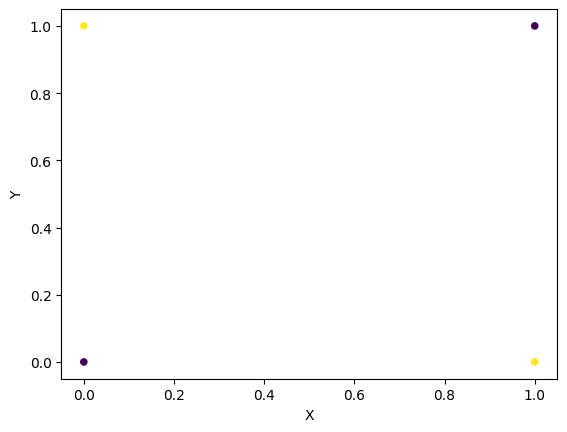

In [ ]:
x_features = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_labels = np.array([0, 1, 1, 0])
scatter_plot_dataset(x_features, y_labels, x_plot_dimension=0, y_plot_dimension=1)

### Cell for Your Code

Uncomment your selected lines in the cell below.

In [ ]:
# This class implements a simple neural network. **You will need to modify it
# by uncommenting your lines of choice.**
class ToyNeuralNetwork:
    """Implements a toy neural network for academic exercises."""

    def __init__(self) -> None:
        """Initialize a toy neural network."""
        self.b1 = np.array([0, 0])
        self.w1 = np.array([[1, -1], [-1, 1]])
        self.w2 = np.array([1, 1])
        self.b2 = 0

    def forward(self, x: np.ndarray) -> np.ndarray:
        """Pass data through the toy neural network."""

        # Choice A:
        # x = np.maximum(0, x @ self.w1 @ self.w2) + self.b2

        # Choice B:
        # x = x @ self.w1 + self.b1
        # x = x @ self.w2 + self.b2
        # x = np.maximum(0, x)

        # Choice C:
        # k = -1
        # x = np.maximum(0, x @ self.w1 + self.b1)
        # x = k * (x @ self.w2) + self.b2

        # Choice D:
        # x = x @ self.w1 + self.b1
        # x = np.maximum(0, x)
        # x = x @ self.w2 + self.b2

        # Choice E:
        # x = x @ self.w1 - self.b1
        # x = x @ self.w2 + self.b2

        return x

### Check Your Work

Use the visualizations to check your work.

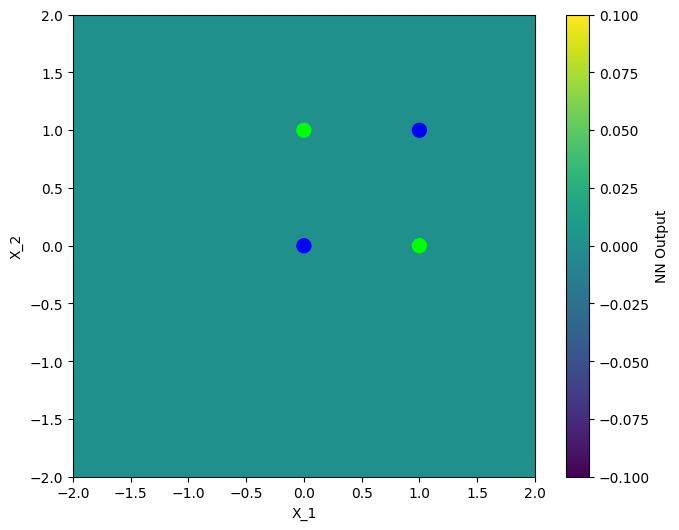

In [10]:
# Here we instantiate a neural network from our class
nn = ToyNeuralNetwork()

# This line plots the output of our neural network as a surface. This
# should help you decide which choice to make for problem 03 - part A. You
# can see the visual in ./nn_output.jpg.
plot_2d_decision_surface_and_features(
    x_features,
    y_labels,
    x_range=(-2, 2),
    y_range=(-2, 2),
    n_grid_points=25,
    plot_function=nn.forward,
)

## Problem 15: Inheritance

Select the lines of code which:
* Create a child of the ToyCNN class
* Correctly call the ToyCNN `__init__` function during the `__init__` for the child and uses the values of `kernel` and `bias` that were initialized during the initialization of ToyCNN
* Use the "swish" activation instead of the ReLU activation (you are encouraged to look up the swish activation)

### Setup

This code defines the parent class. You do not need to modify it.

In [ ]:
class ToyCNN:
    def __init__(self, kernel_size: int) -> None:
        self.kernel = np.ones(kernel_size)
        self.bias = 0

    def activation(self, x: np.ndarray) -> np.ndarray:
        return np.maximum(0, x)

    def conv1d(self, x: np.ndarray) -> np.ndarray:
        conv_output = np.convolve(x, self.kernel, mode="valid") + self.bias
        return conv_output

    def forward(self, x: np.ndarray) -> np.ndarray:
        conv_output = self.conv1d(x)
        return self.activation(conv_output)


cnn = ToyCNN(kernel_size=3)
x = np.array([1, 2, 3, 4, 5])
output = cnn.forward(x)

### Student Code

Uncomment your selected lines in the cell below.

In [ ]:
# Choice A:
# class ChildCNN(ToyCNN):
#     def __init__(self, kernel_size, beta=1):
#         self.beta = beta
#         super().__init__(kernel_size)
#         print("Initialized child.")
#     def swish(self, x):
#         return x / (1 + np.exp(-self.beta * x))

# Choice B:
# class ChildCNN(ToyCNN):
#     def __init__(self, kernel_size, beta=1):
#         self.beta = beta
#         self.kernel = np.ones(kernel_size)
#         self.bias = 0
#         print("Initialized child.")
#     def activation(self, x):
#         return x / (1 + np.exp(-self.beta * x))

# Choice C:
# class ChildCNN(ToyCNN):
#     def __init__(self, kernel_size, beta=1):
#         self.beta = beta
#         super().__init__(kernel_size)
#         print("Initialized child.")
#     def activation(self, x):
#         return x / (1 + np.exp(-self.beta * x))

# Choice D:
# class ChildCNN(ToyCNN):
#     def __init__(self, kernel_size, beta=1):
#         self.beta = beta
#         self.kernel = np.random.randn(kernel_size)
#         self.bias = np.random.randn()
#         print("Initialized child.")
#     def swish(self, x):
#         return activation(x)

### Check your work

Use the outputs to check your work.

In [ ]:
# ChildCNN is defined when you uncomment a choice in Problem 15.
child_cnn = ChildCNN(kernel_size=2)  # type: ignore[name-defined]  # noqa: F821
x = np.array([1, 2, 3, 4, 5])
output = child_cnn.forward(x)
print(output)

## Problem 16: Data Loading

The following function generates a simple dataset as a numpy array.

Select the option that builds a PyTorch `Dataset` from this array. Your dataset must:
* Inherit from the `Dataset` class,
* Be able to return elements using the `[]` notation once instantiated,
* Be able to return its length using the Python builtin `len` function,
* Return both the sample value and the label value as a tuple when indexed with `[]`.

Read each choice carefully and be sure the choice you select meets all these criteria!

### Setup

This code generates some data. You do not need to modify it.

In [ ]:
n_samples_per_class = 100
x_features, y_labels, labels = generate_xor_dataset(n_samples_per_class, sigma=0.1)

In [ ]:
# Choice A:
# class NumpyDataset(Dataset):
#     def __init__(self, x_features_array, y_labels, transform=None):
#         self.data = x_features_array
#         self.labels = y_labels
#         self.transform = transform

#     def __len__(self):
#         return len(self.data)

#     def __getitem__(self, idx):
#         sample = self.data[idx]
#         label = self.labels[idx]
#         if self.transform:
#             sample = self.transform(sample)
#         sample = torch.tensor(sample, dtype=torch.float32)
#         label = torch.tensor(label, dtype=torch.float32)
#         return (sample,)


# Choice B:
# class NumpyDataset(Dataset):
#     def __init__(self, x_features_array, y_labels, transform=None):
#         self.data = x_features_array
#         self.labels = y_labels
#         self.transform = transform

#     def __len__(self):
#         return len(self.data)

#     def __getitem__(self, idx):
#         sample = self.data[idx]
#         label = self.labels[idx]
#         if self.transform:
#             sample = self.transform(sample)
#         sample = torch.tensor(sample, dtype=torch.float32)
#         label = torch.tensor(label, dtype=torch.float32)
#         return sample, label


# Choice C:
# class NumpyDataset(Dataset):
#     def __init__(self, x_features_array, y_labels, transform=None):
#         self.data = x_features_array
#         self.labels = y_labels
#         self.transform = transform

#     def __len__(self):
#         return len(self.data[0])

#     def __getitem__(self, idx):
#         sample = self.data[idx]
#         label = self.labels[idx]
#         if self.transform:
#             sample = self.transform(sample)
#         sample = torch.tensor(sample, dtype=torch.float32)
#         label = torch.tensor(label, dtype=torch.float32)
#         return sample, label

In [63]:
# NumpyDataset is defined when you uncomment a choice in Problem 16.
torch_dataset = NumpyDataset(x_features, y_labels)  # type: ignore[name-defined]  # noqa: F821

print(f"First entry of dataset: {torch_dataset[0]}")
print(f"Second entry of dataset: {torch_dataset[1]}")
print(f"Length of dataset: {len(torch_dataset)}")
print(f"Dataset type: {type(torch_dataset)}")

First entry of dataset: (tensor([-0.0241, -0.0626]),)
Second entry of dataset: (tensor([0.0352, 0.0396]),)
Length of dataset: 200
Dataset type: <class '__main__.NumpyDataset'>


## Problem 17: Transformations

Select the code snippet which correctly implements a transform that shifts the first column of each sample by 10 and then flips both columns about 0.

In [ ]:
# # Choice A:
# class Flip:
#     def __call__(self, vector):
#         return -vector


# class Shift:
#     def __call__(self, vector):
#         vector = vector.copy()
#         vector[0] += 10
#         return vector


# transform = v2.Compose(
#     [
#         Shift(),
#         Flip(),
#     ]
# )


# # Choice B
# class Shift:
#     def __call__(self, vector):
#         vector = vector.copy()
#         vector[1] += 10
#         return vector


# class Flip:
#     def __call__(self, vector):
#         return -vector


# transform = v2.Compose(
#     [
#         Flip(),
#         Shift(),
#     ]
# )

# Choice C
# class Shift:
#     def __call__(self, vector):
#         vector = vector.copy()
#         vector[1] += 10
#         return vector

# class Flip:
#     def __call__(self, vector):
#         return vector - 1


# transform = v2.Compose(
#     [
#         Flip(),
#         Shift(),
#     ]
# )

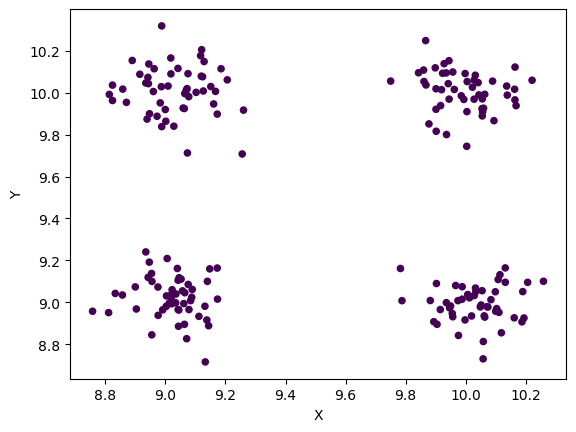

In [74]:
# NumpyDataset and transform are defined by your choices in Problems 16 and 17.
transformed_dataset = NumpyDataset(x_features, y_labels, transform=transform)  # type: ignore[name-defined]  # noqa: F821

transformed_samples = np.zeros(transformed_dataset.data.shape)
for idx, sample in enumerate(transformed_dataset):
    transformed_samples[idx, :] = sample[0].detach().numpy()

scatter_plot_dataset(
    transformed_samples,
    np.zeros(len(transformed_dataset.data)),
    x_plot_dimension=0,
    y_plot_dimension=1,
)